# 05 - Sentiment and PMI drift

This notebook presents the completed full-data sentiment and PMI artifacts produced by the command-line pipeline. It does **not** rescan prepared reviews, rerun VADER, or recompute PMI counts.

In [4]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'pyproject.toml').is_file():
            return candidate
    raise FileNotFoundError('Could not locate project root containing pyproject.toml')

ROOT = find_project_root(Path.cwd())
INPUT_DIR = ROOT / 'artifacts' / 'sentiment'
OUTPUT_DIR = ROOT / 'artifacts' / 'sentiment'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

table_path = INPUT_DIR / 'sentiment_by_sector_period.csv'
summary_path = INPUT_DIR / 'sentiment_summary.json'
sentiment = pd.read_csv(table_path, dtype={'period': str})
summary = json.loads(summary_path.read_text(encoding='utf-8'))
sentiment

,sector,period,review_count,mean_compound,compound_ci_lower,compound_ci_upper,positive_share,neutral_share,negative_share,mean_stars
0,Italian Restaurants,2005,63,0.673283,0.577541,0.769024,0.857143,0.063492,0.079365,3.968254
1,Italian Restaurants,2006,333,0.701877,0.653398,0.750355,0.885886,0.030030,0.084084,3.981982
2,Italian Restaurants,2007,1076,0.750995,0.726785,0.775206,0.923792,0.009294,0.066914,3.868030
3,Italian Restaurants,2008,3324,0.755744,0.740564,0.770924,0.907942,0.011733,0.080325,3.735259
4,Italian Restaurants,2009,5548,0.743098,0.730847,0.755349,0.903749,0.009193,0.087058,3.655732
5,Italian Restaurants,2010,10526,0.748187,0.739491,0.756882,0.906137,0.009405,0.084458,3.691526
6,Italian Restaurants,2011,16938,0.735355,0.728227,0.742482,0.897981,0.010096,0.091923,3.678770
7,Italian Restaurants,2012,21712,0.721135,0.714692,0.727578,0.890613,0.011100,0.098287,3.668156
8,Italian Restaurants,2013,27363,0.703938,0.697947,0.709930,0.881446,0.010818,0.107737,3.673501
9,Italian Restaurants,2014,35563,0.694589,0.689267,0.699911,0.875798,0.011388,0.112814,3.727048


In [5]:
expected_columns = {
    'sector', 'period', 'review_count', 'mean_compound',
    'compound_ci_lower', 'compound_ci_upper',
    'positive_share', 'neutral_share', 'negative_share', 'mean_stars',
}
assert expected_columns == set(sentiment.columns)
assert len(sentiment) == summary['period_rows']
assert sentiment['review_count'].sum() == summary['audit']['sector_review_assignments']
assert np.allclose(
    sentiment[['positive_share', 'neutral_share', 'negative_share']].sum(axis=1),
    1.0,
)

pd.DataFrame({
    'metric': [
        'reviews read', 'matched reviews', 'multi-sector reviews',
        'sector-review assignments', 'missing categories', 'period rows',
    ],
    'value': [
        summary['audit']['reviews_read'],
        summary['audit']['matched_reviews'],
        summary['audit']['multi_sector_reviews'],
        summary['audit']['sector_review_assignments'],
        summary['audit']['reviews_without_categories'],
        summary['period_rows'],
    ],
})

,metric,value
0,reviews read,6990280
1,matched reviews,660089
2,multi-sector reviews,12277
3,sector-review assignments,672366
4,missing categories,689
5,period rows,36


## Method

Each original review string was scored once with VADER. Reviews were assigned to every configured sector whose required Yelp categories were present, then aggregated by calendar year. Lines show the mean VADER compound score; shaded regions show 95% normal-approximation confidence intervals computed from online sample variance. The lower panel retains review counts so apparent trends can be judged against sample size.

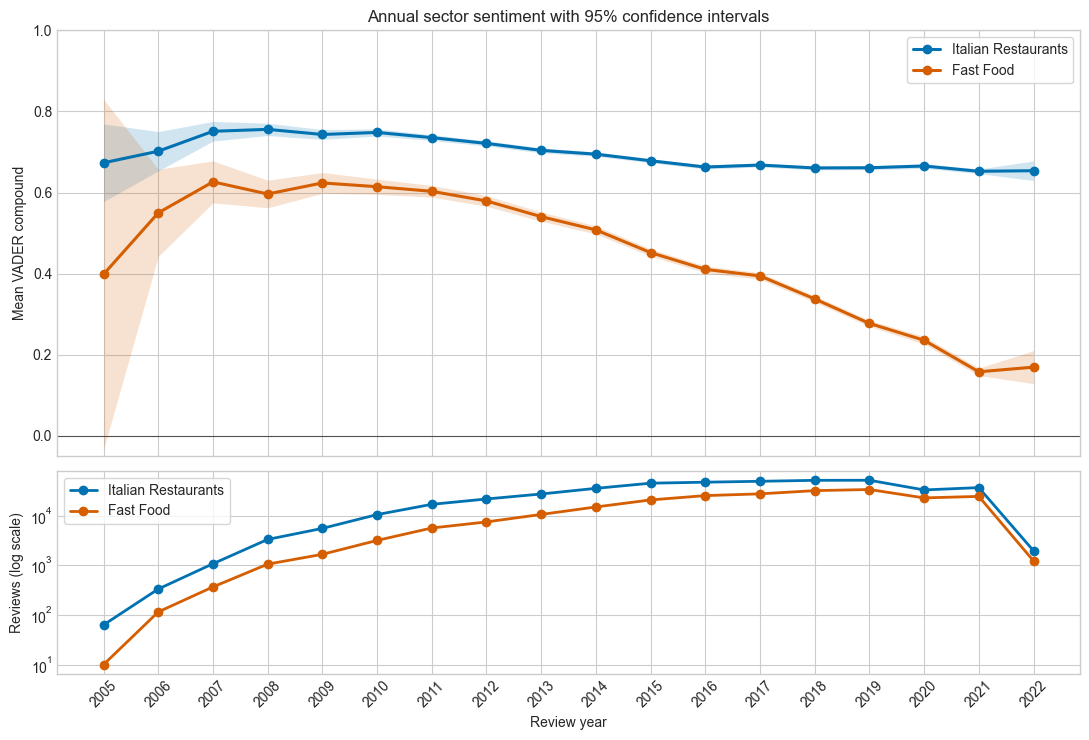

WindowsPath('F:/1_graduates/text_management/group/artifacts/sentiment/sentiment_annual_trend_report.png')

In [6]:
plt.style.use('seaborn-v0_8-whitegrid')
colors = dict(zip(sentiment['sector'].drop_duplicates(), ['#0072B2', '#D55E00']))
fig, (score_ax, count_ax) = plt.subplots(
    2, 1, figsize=(11, 7.5), sharex=True, height_ratios=(2.1, 1)
)

for sector, frame in sentiment.groupby('sector', sort=False):
    frame = frame.sort_values('period')
    years = frame['period'].astype(int).to_numpy()
    color = colors[sector]
    score_ax.plot(
        years, frame['mean_compound'], marker='o', linewidth=2.2,
        color=color, label=sector,
    )
    score_ax.fill_between(
        years, frame['compound_ci_lower'], frame['compound_ci_upper'],
        color=color, alpha=0.18, linewidth=0,
    )
    count_ax.plot(
        years, frame['review_count'], marker='o', linewidth=2.0,
        color=color, label=sector,
    )

score_ax.axhline(0, color='black', linewidth=0.8, alpha=0.6)
score_ax.set(title='Annual sector sentiment with 95% confidence intervals', ylabel='Mean VADER compound')
score_ax.set_ylim(-0.05, 1.0)
score_ax.legend(frameon=True)
count_ax.set(ylabel='Reviews (log scale)', xlabel='Review year', yscale='log')
count_ax.legend(frameon=True)
count_ax.set_xticks(sorted(sentiment['period'].astype(int).unique()))
count_ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
trend_figure = OUTPUT_DIR / 'sentiment_annual_trend_report.png'
fig.savefig(trend_figure, dpi=220, bbox_inches='tight')
plt.show()
trend_figure

## Sentiment-class composition

VADER's conventional compound thresholds classify reviews as positive (at least 0.05), neutral (between -0.05 and 0.05), or negative (at most -0.05). Shares are shown alongside the mean so a change in the mean is not interpreted without its underlying class composition.

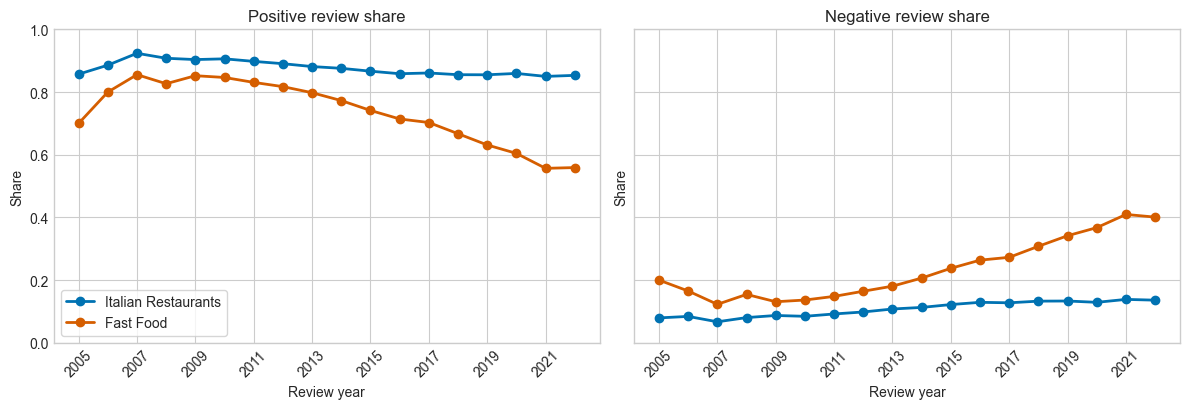

WindowsPath('F:/1_graduates/text_management/group/artifacts/sentiment/sentiment_class_shares_report.png')

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True, sharey=True)
share_specs = [
    ('positive_share', 'Positive review share'),
    ('negative_share', 'Negative review share'),
]
for axis, (column, title) in zip(axes, share_specs):
    for sector, frame in sentiment.groupby('sector', sort=False):
        frame = frame.sort_values('period')
        axis.plot(
            frame['period'].astype(int), frame[column], marker='o',
            linewidth=2, color=colors[sector], label=sector,
        )
    axis.set(title=title, xlabel='Review year', ylabel='Share')
    axis.set_ylim(0, 1)
    axis.set_xticks(sorted(sentiment['period'].astype(int).unique())[::2])
    axis.tick_params(axis='x', rotation=45)
axes[0].legend(frameon=True)
fig.tight_layout()
share_figure = OUTPUT_DIR / 'sentiment_class_shares_report.png'
fig.savefig(share_figure, dpi=220, bbox_inches='tight')
plt.show()
share_figure

## Descriptive comparison table

The table below is computed from the aggregate artifact. `weighted_mean_compound` weights annual means by their review counts. Endpoint changes should be interpreted together with the endpoint sample sizes, especially for partial or sparse years.

In [8]:
comparison_rows = []
for sector, frame in sentiment.groupby('sector', sort=False):
    frame = frame.sort_values('period')
    first, last = frame.iloc[0], frame.iloc[-1]
    comparison_rows.append({
        'sector': sector,
        'reviews': int(frame['review_count'].sum()),
        'first_year': first['period'],
        'first_year_n': int(first['review_count']),
        'first_mean': first['mean_compound'],
        'last_year': last['period'],
        'last_year_n': int(last['review_count']),
        'last_mean': last['mean_compound'],
        'endpoint_change': last['mean_compound'] - first['mean_compound'],
        'weighted_mean_compound': np.average(
            frame['mean_compound'], weights=frame['review_count']
        ),
        'weighted_mean_stars': np.average(
            frame['mean_stars'], weights=frame['review_count']
        ),
    })
comparison = pd.DataFrame(comparison_rows)
comparison_path = OUTPUT_DIR / 'sentiment_sector_summary.csv'
comparison.to_csv(comparison_path, index=False)
comparison.round(4)

,sector,reviews,first_year,first_year_n,first_mean,last_year,last_year_n,last_mean,endpoint_change,weighted_mean_compound,weighted_mean_stars
0,Italian Restaurants,439358,2005,63,0.6733,2022,1964,0.6538,-0.0195,0.6786,3.7811
1,Fast Food,233008,2005,10,0.3984,2022,1227,0.1693,-0.2291,0.3658,3.0286


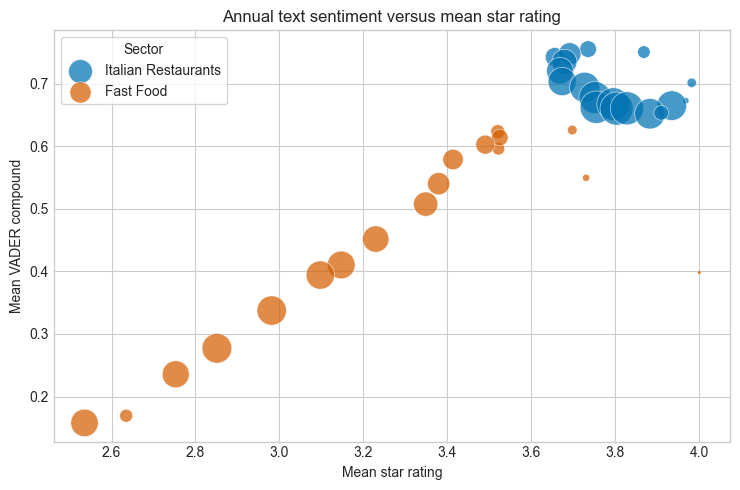

WindowsPath('F:/1_graduates/text_management/group/artifacts/sentiment/sentiment_vs_stars_report.png')

In [9]:
fig, axis = plt.subplots(figsize=(7.5, 5))
for sector, frame in sentiment.groupby('sector', sort=False):
    axis.scatter(
        frame['mean_stars'], frame['mean_compound'],
        s=np.sqrt(frame['review_count']) * 2.5, alpha=0.72,
        color=colors[sector], label=sector, edgecolor='white', linewidth=0.5,
    )
axis.set(
    title='Annual text sentiment versus mean star rating',
    xlabel='Mean star rating', ylabel='Mean VADER compound',
)
axis.legend(frameon=True, title='Sector')
fig.tight_layout()
stars_figure = OUTPUT_DIR / 'sentiment_vs_stars_report.png'
fig.savefig(stars_figure, dpi=220, bbox_inches='tight')
plt.show()
stars_figure

## Interpretation and limitations

Before writing the report, interpret changes together with review counts and confidence intervals, distinguish association from causation, and disclose that 12,277 reviews belong to both configured sectors. VADER is lexicon-based: it does not reliably resolve sarcasm, domain-specific meanings, the target of an opinion, or mixed sentiment within a review. A single compound score can therefore hide statements such as positive food sentiment combined with negative service sentiment. Changes may also reflect shifts in the reviewer population or dataset coverage rather than changes in the businesses themselves.

## PMI drift

This section reads the completed full-data PMI artifacts; it does not rescan the review JSONL. The centre term is `service`. For each occurrence, the implementation uses a symmetric five-token raw-position window. Stop words, conjunctions, and punctuation are ineligible as centre/context terms but retain their positions, so removing them does not artificially close the window. Counts are independent by year and use directed centre-to-context pair events.

A context term is eligible in a year when its co-occurrence count is at least `max(10, ceil(0.001 * target_pair_events))`; the table then retains the annual top 20 by PMI. Thus the relative floor can be read as `P(context | centre=service) >= 0.001`.

In [ ]:
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PMI_DIR = ROOT / 'artifacts' / 'pmi'
PMI_DIR.mkdir(parents=True, exist_ok=True)
PMI_TABLE = PMI_DIR / 'pmi_drift_service_by_year.csv'
PMI_SUMMARY = PMI_DIR / 'pmi_drift_service_summary.json'

pmi = pd.read_csv(PMI_TABLE, dtype={'period': str})
pmi_summary = json.loads(PMI_SUMMARY.read_text(encoding='utf-8'))

expected_columns = [
    'period', 'target_term', 'associated_term', 'rank', 'cooccurrence',
    'target_occurrences', 'target_pair_events', 'context_frequency',
    'total_pair_events', 'pmi',
]
assert list(pmi.columns) == expected_columns
assert len(pmi) == pmi_summary['ranked_rows']
assert pmi['target_term'].unique().tolist() == [pmi_summary['target_term']] == ['service']
recomputed = np.log2(
    pmi['cooccurrence'] * pmi['total_pair_events']
    / (pmi['target_pair_events'] * pmi['context_frequency'])
)
assert np.allclose(pmi['pmi'], recomputed, rtol=1e-10, atol=1e-10)

period_audit = pd.DataFrame(pmi_summary['periods'])
period_audit['period'] = period_audit['period'].astype(str)
thresholds = period_audit.set_index('period')['effective_min_cooccurrence']
assert (pmi['cooccurrence'] >= pmi['period'].map(thresholds)).all()
assert period_audit['ranked_terms'].sum() == len(pmi)

period_audit.to_csv(PMI_DIR / 'pmi_period_summary.csv', index=False)
print(f"Validated {len(pmi):,} ranked rows across {pmi['period'].nunique()} years.")
pd.DataFrame([pmi_summary['audit']])


In [ ]:
period_audit[[
    'period', 'reviews', 'reviews_with_target', 'target_occurrences',
    'target_pair_events', 'effective_min_cooccurrence',
    'candidate_terms', 'ranked_terms',
]].style.format({
    'reviews': '{:,}', 'reviews_with_target': '{:,}',
    'target_occurrences': '{:,}', 'target_pair_events': '{:,}',
    'effective_min_cooccurrence': '{:,}',
})


### Persistent associations

The heatmap uses the terms selected by the analysis command: a term must appear in the annual top 20 in at least four years, after which candidates are ordered by persistence, median rank, and median PMI. A blank cell means that the term did not enter that year's top 20; it does **not** mean PMI equals zero.

In [ ]:
selected_terms = pmi_summary['heatmap_selection']['terms']
period_order = period_audit['period'].tolist()
heat = (pmi.pivot(index='period', columns='associated_term', values='pmi')
        .reindex(index=period_order, columns=selected_terms))

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    heat.T, mask=heat.T.isna(), cmap='YlOrRd',
    linewidths=0.35, linecolor='white', cbar_kws={'label': 'PMI'}, ax=ax,
)
ax.set_title("Persistent annual PMI associations with 'service'", pad=14)
ax.set_xlabel('Year')
ax.set_ylabel('Associated term')
plt.xticks(rotation=45, ha='right')
fig.tight_layout()
heatmap_report = PMI_DIR / 'pmi_service_persistent_heatmap_report.png'
fig.savefig(heatmap_report, dpi=180, bbox_inches='tight')
plt.show()


In [ ]:
term_summary = (pmi[pmi['associated_term'].isin(selected_terms)]
    .groupby('associated_term', as_index=False)
    .agg(years_present=('period', 'nunique'), median_rank=('rank', 'median'),
         median_pmi=('pmi', 'median'), total_cooccurrence=('cooccurrence', 'sum'))
    .sort_values(['years_present', 'median_rank', 'median_pmi', 'associated_term'],
                 ascending=[False, True, False, True]))
term_summary.to_csv(PMI_DIR / 'pmi_service_term_summary.csv', index=False)

trajectory_terms = term_summary.head(8)['associated_term'].tolist()
rank_wide = (pmi[pmi['associated_term'].isin(trajectory_terms)]
             .pivot(index='period', columns='associated_term', values='rank')
             .reindex(period_order))
fig, ax = plt.subplots(figsize=(12, 6.5))
for term in trajectory_terms:
    ax.plot(rank_wide.index, rank_wide[term], marker='o', markersize=3.5,
            linewidth=1.5, label=term)
ax.set_title("Rank trajectories of persistent associations with 'service'")
ax.set_xlabel('Year')
ax.set_ylabel('Annual PMI rank (1 = strongest)')
ax.set_ylim(20.5, 0.5)
ax.set_yticks(range(1, 21))
ax.tick_params(axis='x', rotation=45)
ax.legend(ncol=2, frameon=True)
fig.tight_layout()
trajectory_report = PMI_DIR / 'pmi_service_rank_trajectories_report.png'
fig.savefig(trajectory_report, dpi=180, bbox_inches='tight')
plt.show()
term_summary


### Representative years

The following compact table samples the beginning, middle, disruption period, and end of the series. It reports both PMI and co-occurrence, because a high PMI value alone does not imply that an association is frequent.

In [ ]:
representative_years = ['2006', '2010', '2015', '2020', '2022']
representative = (pmi[pmi['period'].isin(representative_years)]
    .query('rank <= 10')
    [['period', 'rank', 'associated_term', 'pmi', 'cooccurrence']]
    .sort_values(['period', 'rank']))
representative.to_csv(PMI_DIR / 'pmi_service_representative_years.csv', index=False)
representative.style.format({'pmi': '{:.3f}', 'cooccurrence': '{:,}'})


### Interpretation and limitations

Interpret the heatmap as changes in lexical association, not as a direct measure of service quality or a causal effect. PMI rewards specificity and can elevate relatively uncommon pairs, so each claim should be checked against `cooccurrence` and the yearly review volume. Missing heatmap cells mean outside the annual top 20, not zero association. The 2005 estimate is based on only 854 reviews, while 2022 is a partial final year in this dataset; neither is directly comparable to a complete high-volume year without that qualification. Results also depend on tokenization, the five-token window, stop-word eligibility, the 0.001 support floor, and the choice of `service` as the single centre term.